In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

import numpy

import matplotlib.pyplot as plt

## Загрузка данных MNIST

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1037, ), (0.8031, ))
])

train_dataset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)

print(f"Количество выборки обучения: {len(train_dataset)}")
print(f"Количество выборки тестирования: {len(test_dataset)}")

Количество выборки обучения: 60000
Количество выборки тестирования: 10000


## Создание батчей изображений

In [4]:
batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Количество батчей обучения: {len(train_loader)}")
print(f"Количество батчей тестирования: {len(test_loader)}")

Количество батчей обучения: 469
Количество батчей тестирования: 79


## Визуализация данных

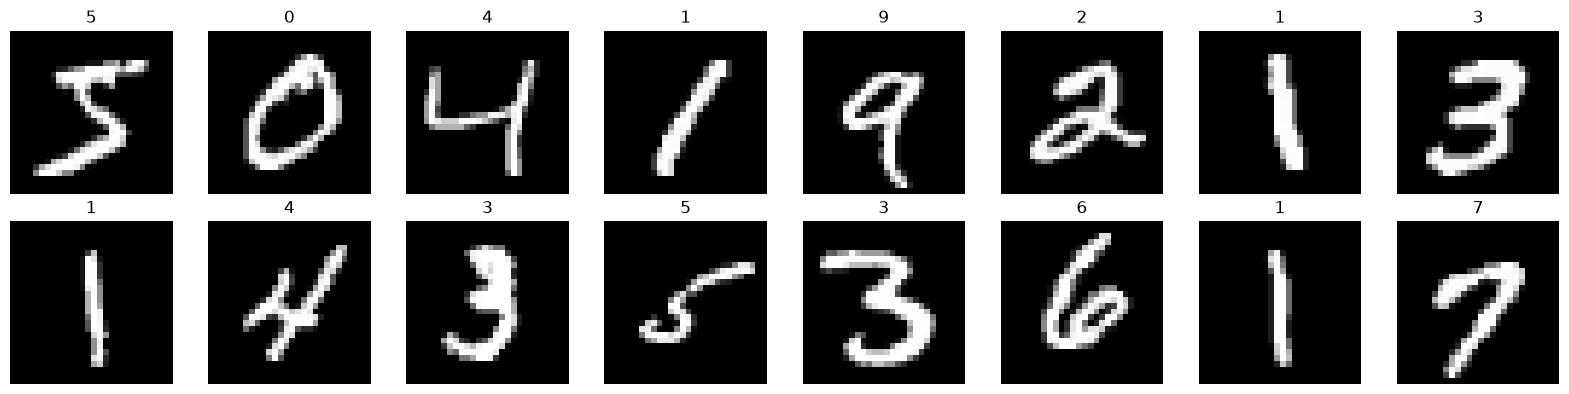

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i, ax in enumerate(axes.flatten()):
    img, label = train_dataset[i]
    img_display = img.squeeze().numpy() * 0.3081 + 0.1037
    ax.imshow(img_display, cmap='gray')
    ax.set_title(label, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Создание класса MLP модели

In [6]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_size=[256, 128], num_classes=10):
        super(MLP, self).__init__()

        layers = []
        prev = input_size

        for h in hidden_size:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())

            prev = h
        layers.append(nn.Linear(prev, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.network(x)

model = MLP()
total_param = sum(p.numel() for p in model.parameters())

# (784*256 + 256) + (256*128 + 128) + (128*10 + 10) = 235146 - сумма параметров трёх слоев
print(f"Общее количество параметров: {total_param}")

Общее количество параметров: 235146


## Обучение

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

n_epochs = 10

train_losses = []
train_accs = []
test_accs = []

for epoch in range(n_epochs):
    model.train()

    running_losses = 0.0
    correct_train = 0
    total_train = 0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_losses += loss.item() * batch_X.size(0)
        _, predicted = torch.max(outputs, 1)
        correct_train += (predicted == batch_y).sum().item()
        total_train += batch_y.size(0)


    epoch_train_losses = running_losses / total_train
    epoch_train_accs = correct_train / total_train
    train_losses.append(epoch_train_losses)
    train_accs.append(epoch_train_accs)

    model.eval()

    correct_test = 0
    total_test = 0 

    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            outputs = model(batch_X)

            _, predicted = torch.max(outputs, 1)
            correct_test += (predicted == batch_y).sum().item()
            total_test += batch_y.size(0)

    epoch_test_accs = correct_test / total_test
    test_accs.append(epoch_test_accs)

    print(
        f"Эпоха {epoch + 1}/{n_epochs}: "
        f"train_losses={epoch_train_losses:.4f} | "
        f"train_accs={epoch_train_accs:.4f} | "
        f"test_accs={epoch_test_accs:.4f}"
    )





Эпоха 1/10: train_losses=0.0230 | train_accs=0.9924 | test_accs=0.9797
Эпоха 2/10: train_losses=0.0167 | train_accs=0.9944 | test_accs=0.9794
Эпоха 3/10: train_losses=0.0134 | train_accs=0.9958 | test_accs=0.9793
Эпоха 4/10: train_losses=0.0131 | train_accs=0.9954 | test_accs=0.9794
Эпоха 5/10: train_losses=0.0118 | train_accs=0.9959 | test_accs=0.9799
Эпоха 6/10: train_losses=0.0099 | train_accs=0.9965 | test_accs=0.9782
Эпоха 7/10: train_losses=0.0094 | train_accs=0.9969 | test_accs=0.9789
Эпоха 8/10: train_losses=0.0072 | train_accs=0.9973 | test_accs=0.9778
Эпоха 9/10: train_losses=0.0131 | train_accs=0.9954 | test_accs=0.9796
Эпоха 10/10: train_losses=0.0062 | train_accs=0.9979 | test_accs=0.9823
